## Quadro completo del Notebook 1

- **Sezione 1 — Setup, Configurazione e Percorsi**
    - 1.1 Librerie, parametri globali (rendering, label, gate) e creazione directory
- **Sezione 2 — Scoperta Simulazioni e Ispezione Dati**
    - 2.1 `header_summary`: Lettura metadati (BoxSize, cosmologia, massa DM)
    - 2.2 `inspect_hdf5`: Dump strutturale di Snapshot e Cataloghi per documentare i campi letti
- **Sezione 3 — Snapshot e Smoothing Lengths**
    - 3.1 `file_md5` e `load_snapshot`: Lettura particelle DM e coordinate
    - 3.2 `get_smoothing_lengths`: Calcolo del raggio SPH con cache persistente
- **Sezione 4 — Proiezione SPH e Calibrazione di Massa**
    - 4.1 `render_slices`: Selezione fette z e proiezione densità $\rho(x,y)$ su griglia $1024^2$
    - 4.2 Calcolo del fattore `mpu` (massa per unità) per la conversione pixel $\to$ massa fisica
- **Sezione 5 — Normalizzazione del Campo di Densità**
    - 5.1 `normalize_slices`: Trasformazione log10 + z-score robusto
    - 5.2 Gestione dei pixel vuoti (`EMPTY_FILL = -3.0`)
- **Sezione 6 — Catalogo FoF e Maschere Binarie**
    - 6.1 `load_halo_catalog`: Estrazione posizioni, $R_{200c}$ e taglio in massa
    - 6.2 `make_labels`: Costruzione geometrica dei dischi con periodicità in x-y
- **Sezione 7 — Gate di Registrazione ed Estrazione Patches**
    - 7.1 `registration_check`: Hard gate per verificare l'allineamento densità-maschere
    - 7.2 `extract_patches`: Suddivisione delle fette $1024^2$ in griglie $4\times4$ di patch $256^2$
- **Sezione 8 — Esecuzione della Pipeline**
    - 8.1 `process_simulation`: Orchestrazione completa (rendering $\to$ maschere $\to$ salvataggio)
    - 8.2 Loop multi-simulazione e gestione delle eccezioni
- **Sezione 9 — Output e Compatibilità**
    - 9.1 Riepilogo dei file salvati (`X_patches.npy`, `Y_mask_patches.npy`, `dataset_info.json`, ecc.)
- **Sezione 10 — Visualizzazione del Processo 3D $\to$ 2D $\to$ Patch**
    - 10.1 Plot esplorativo (Scatter 3D, fetta 2D, patch singola)
    - 10.2 Sanity check visivo delle patch di input con contorni delle maschere
- **Sezione 11 — Verifica Visiva delle Maschere**
    - 11.1 `check_patch`: Sovrapposizione della maschera salvata con i cerchi analitici $R_{200c}$

# Patches multi-simulazione (CAMELS LH, snapshot 090) — v1.1.0

Trasforma lo snapshot 3D di materia oscura + catalogo FoF di ogni simulazione
CAMELS LH in patches 2D pronte per la U-Net:

    snapshot + catalogo FoF
      → 25 fette lungo z (proiezione SPH della densità, immagini 1024×1024)
      → normalizzazione log10 + z-score robusto
      → maschere binarie (dischi R_200c dal catalogo, periodiche in x-y)
      → patches 256×256 → input_data/sim_<RUN>_<TAG>/

## Output per simulazione

| File | Contenuto | Shape |
|---|---|---|
| `X_patches.npy` | input (densità normalizzata) | (400, 1, 256, 256) float32 |
| `Y_mask_patches.npy` | target (maschera FoF binaria) | (400, 1, 256, 256) uint8 |
| `norm_stats.npy` | mediana e sigma della normalizzazione | (1, 2) float32 |
| `mpu_per_slice.npy` | massa per unità, per fetta (calibrazione stadio 2) | (25,) float64 |
| `raw_slice_sample.npy` | **fetta `RAW_SAMPLE_SLICE` prima della normalizzazione** (v1.1.0) | (1024, 1024) float32 |
| `dataset_info.json` | metadati completi | — |

## 1 — Setup: librerie, configurazione, comportamento di esecuzione

### Comportamento di esecuzione (v1.1.0)

Due flag controllano cosa succede quando il notebook viene rieseguito:

- **`SKIP_EXISTING = True`**: se `X_patches.npy`, `Y_mask_patches.npy` e
  `dataset_info.json` esistono già, la simulazione viene saltata. Le patch sono
  considerate definitive.
- **`BACKFILL_EXTRAS = True`**: se le patch esistono ma **mancano** i file
  introdotti in v1.1.0 (`raw_slice_sample.npy`) o i metadati nuovi, vengono
  generati **senza** toccare X e Y. Costa ~1-2 min per simulazione perché h è in
  cache. Con questo flag, rieseguire il notebook è sicuro: le patch non vengono
  mai riscritte.

Se hai bisogno di **rigenerare** una simulazione da zero, cancella la sua cartella
`input_data/sim_<id>/` e riesegui: verrà rifatta tutta la pipeline.

### `RAW_SAMPLE_SLICE`

Fetta (`0..24`) di cui salviamo la densità **grezza pre-normalizzazione** in
`raw_slice_sample.npy`. Serve come ground-truth per verificare in nb3 che la
catena `X_patches.npy → denorm → raw` ricostruisca esattamente il campo densità
originale (protegge da bug di ordine patch, base del log, off-by-one).

Valore di default: `12` (fetta centrale, ben popolata).

In [1]:
# ============================================================
# LIBRERIE
# ============================================================
import os, gc, time, json, hashlib, traceback
from datetime import datetime

import numpy as np
import re
import h5py
import hdf5plugin                                       # richiesto per gli snapshot compressi (bitshuffle)
import pandas as pd

import sphviewer2                                       # type: ignore
from sphviewer2 import estimate_h, render               # type: ignore

# ============================================================
# CONFIGURAZIONE (unica fonte di verità)
# ============================================================
PIPELINE_VERSION = "1.1.0"

# ---------------- percorsi ----------------
DATA_DIR    = r"C:\Users\kekko\Downloads\Python\TESI\CAMELS_data"
SIM_ROOT    = os.path.join(DATA_DIR, "Simulations")
OUT_ROOT    = os.path.join(DATA_DIR, "input_data")
H_CACHE_DIR = os.path.join(DATA_DIR, "smoothing_lengths_cache")

# ---------------- selezione dati ----------------
SNAP_TAG = "090"                                        # snapshot a z≈0

# ---------------- rendering SPH ----------------
N_NEIGHBORS_H = 32                                      # vicini per lo smoothing length
TARGET_CELLS  = 4                                       # celle per h nel rendering
R_MAX_LEVEL   = 10                                      # griglia: IMG_SIZE = 2**10 = 1024
IMG_SIZE      = 2 ** R_MAX_LEVEL
N_SLICES      = 25                                      # fette lungo z (Δz = 1 Mpc/h)

# ---------------- label e patches ----------------
N_MIN_PARTICLES = 100                                   # taglio catalogo FoF (per-simulazione!)
MIN_RADIUS_PX   = 1.5                                   # raggio minimo delle maschere [px]
PATCH_SIZE      = 256
EMPTY_FILL      = -3.0                                  # valore dei pixel vuoti/non finiti

# ---------------- gate e varie ----------------
REG_MIN_DIRECT = 2.0                                    # densità media minima dentro le maschere
REG_MIN_RATIO  = 3.0                                    # rapporto minimo direct/trasposto
SEED           = 42
NUM_THREADS    = 8

# ---------------- comportamento di esecuzione (v1.1.0) ----------------
SKIP_EXISTING    = True     # se X/Y/info esistono, non rigenera le patch
BACKFILL_EXTRAS  = True     # se X esiste ma mancano file v1.1.0, li aggiunge senza toccare X
RAW_SAMPLE_SLICE = 12       # fetta di cui salvare raw pre-normalizzazione (verifica end-to-end in nb3)

os.makedirs(OUT_ROOT, exist_ok=True)
os.makedirs(H_CACHE_DIR, exist_ok=True)

# ---------------- riepilogo configurazione ----------------
print(f"Pipeline v{PIPELINE_VERSION} | snapshot {SNAP_TAG}")
print(f"  rendering : {N_SLICES} fette × {IMG_SIZE}² | h da k={N_NEIGHBORS_H} vicini")
print(f"  patches   : {PATCH_SIZE}² | griglia {IMG_SIZE // PATCH_SIZE}×{IMG_SIZE // PATCH_SIZE} per fetta")
print(f"  taglio    : N_MIN_PARTICLES = {N_MIN_PARTICLES} (per-simulazione)")
print(f"  esecuzione: SKIP_EXISTING={SKIP_EXISTING} | BACKFILL_EXTRAS={BACKFILL_EXTRAS}")
print(f"  raw sample: fetta {RAW_SAMPLE_SLICE} salvata in raw_slice_sample.npy")
print(f"  percorsi  : DATA_DIR={DATA_DIR}")

Pipeline v1.1.0 | snapshot 090
  rendering : 25 fette × 1024² | h da k=32 vicini
  patches   : 256² | griglia 4×4 per fetta
  taglio    : N_MIN_PARTICLES = 100 (per-simulazione)
  esecuzione: SKIP_EXISTING=True | BACKFILL_EXTRAS=True
  raw sample: fetta 12 salvata in raw_slice_sample.npy
  percorsi  : DATA_DIR=C:\Users\kekko\Downloads\Python\TESI\CAMELS_data


## 2 — Scoperta delle simulazioni

I percorsi sono costruiti **direttamente sul layout fisso di CAMELS** (niente regex o
template multipli: qui il layout è noto e stabile). Se un file manca, la simulazione
viene saltata con un messaggio esplicito — non silenziosamente ignorata.

L'ID simulazione segue la convenzione `<RUN>_<TAG>`, es. `LH_100_090`:
- `RUN` = nome della run cosmologica (`LH_100` … `LH_106`)
- `TAG` = snapshot (`090` = $z \approx 0$)

### Cosa leggiamo dall'Header (senza caricare le coordinate)

Per il riepilogo iniziale serve solo l'Header — nessuna coordinata viene toccata,
quindi il costo è trascurabile ($\sim\mathrm{ms}$ per file). I campi letti sono:

| Campo | Significato | Unità nel file | Conversione |
|---|---|---|---|
| `Redshift` | $z$ dell'output | — | — ($\approx 0$ per lo snapshot 090) |
| `Omega0` | $\Omega_{\mathrm{matter}}$ | — | — |
| `HubbleParam` | $h = H_0/100$ | — | — |
| `BoxSize` | lato della simulazione | $\mathrm{ckpc}/h$ | $\div 1000 \rightarrow \mathrm{Mpc}/h$ |
| `MassTable[1]` | massa particella DM (PartType1) | $10^{10}\,M_\odot/h$ | $\times 10^{10} \rightarrow M_\odot/h$ |
| `NumPart_Total[1]` | numero particelle DM | — | — |

In [2]:
# ============================================================
# SCOPERTA DELLE SIMULAZIONI
# ============================================================
def header_summary(snap_path):
    """Legge solo l'Header dello snapshot (nessuna coordinata).
    Ritorna un dict con i campi fisici rilevanti per il riepilogo."""
    with h5py.File(snap_path, "r") as f:
        hd = f["Header"].attrs
        get = lambda name: float(np.ravel(hd[name])[0]) if name in hd else float("nan")
        return {
            "redshift":  get("Redshift"),
            "omega0":    get("Omega0"),
            "hubble":    get("HubbleParam"),
            "box_mpc":   get("BoxSize") / 1000.0,
            "m_dm":      float(np.ravel(hd["MassTable"])[1]) * 1e10,   # 1e10 Msun/h -> Msun/h
            "n_dm":      int(np.ravel(hd["NumPart_Total"])[1]),
        }


# Costruisce il dizionario {sim_id: (snap_path, cat_path)} scansionando SIM_ROOT
SIMULATIONS = {}
for run in sorted(os.listdir(SIM_ROOT)):
    s = os.path.join(SIM_ROOT, run, f"snapshots_{run}", f"snapshot_{SNAP_TAG}_{run}.hdf5")
    c = os.path.join(SIM_ROOT, run, f"groups_{run}",    f"groups_{SNAP_TAG}_{run}.hdf5")
    if os.path.exists(s) and os.path.exists(c):
        SIMULATIONS[f"{run}_{SNAP_TAG}"] = (s, c)
    else:
        print(f"[skip] {run}: layout incompleto")

print(f"\nSimulazioni trovate: {len(SIMULATIONS)}\n")
print(pd.DataFrame([
    {"sim_id": k, **header_summary(s)} for k, (s, _) in SIMULATIONS.items()
]).to_string(index=False))


Simulazioni trovate: 7

    sim_id     redshift  omega0  hubble  box_mpc         m_dm     n_dm
LH_100_090 2.220446e-16  0.4590  0.6711     25.0 1.186462e+08 16777216
LH_101_090 2.220446e-16  0.1430  0.6711     25.0 3.696386e+07 16777216
LH_102_090 2.220446e-16  0.1194  0.6711     25.0 3.086353e+07 16777216
LH_103_090 2.220446e-16  0.2486  0.6711     25.0 6.426026e+07 16777216
LH_104_090 2.220446e-16  0.3138  0.6711     25.0 8.111371e+07 16777216
LH_105_090 2.220446e-16  0.3726  0.6711     25.0 9.631284e+07 16777216
LH_106_090 2.220446e-16  0.2850  0.6711     25.0 7.366924e+07 16777216


In [3]:
def inspect_hdf5(path, label):
    """Dump completo della struttura di un file HDF5: gruppi, dataset, attributi.
    Cella di esplorazione: eseguita una volta, documenta PERCHÉ la pipeline legge
    esattamente i campi che legge."""
    print(f"\n{'='*60}\n FILE: {label}\n{'='*60}")
    with h5py.File(path, "r") as f:
        for name, node in f.items():
            print(f"\n{'-'*60}\nNODO: {name}\n{'-'*60}\n>>> DATASETS:")
            for ds, d in node.items():
                print(f"    - {ds}  (Shape: {d.shape})")
            if not node.keys():
                print("    (nessuno)")
            print(">>> ATTRIBUTI:")
            for k, v in node.attrs.items():
                v = v.decode() if isinstance(v, bytes) else v
                if isinstance(v, str) and v.lstrip().startswith(("{", "[")):
                    s = re.sub(r"\[([^\[\]{}]*?)\]",
                               lambda m: "[" + re.sub(r"\s+", " ", m.group(1)).strip() + "]",
                               json.dumps(json.loads(v), indent=4))
                    v = "\n        " + s.replace("\n", "\n        ")
                elif isinstance(v, np.ndarray):
                    v = "[" + ", ".join(map(str, v)) + "]"
                print(f"    - {k}: {v}")
            if not node.attrs:
                print("    (nessuno)")

snap_path, cat_path = SIMULATIONS["LH_100_090"]
inspect_hdf5(cat_path,  "groups_090_LH_100.hdf5  (catalogo FoF/Subfind)")
inspect_hdf5(snap_path, "snapshot_090_LH_100.hdf5 (particelle DM)")


 FILE: groups_090_LH_100.hdf5  (catalogo FoF/Subfind)

------------------------------------------------------------
NODO: Config
------------------------------------------------------------
>>> DATASETS:
    (nessuno)
>>> ATTRIBUTI:
    - ALLOW_DIRECT_SUMMATION: 
    - CHUNKING: 
    - DEBUG: 
    - DIRECT_SUMMATION_THRESHOLD: 4000.0
    - DOUBLEPRECISION: 1.0
    - DOUBLEPRECISION_FFTW: 
    - ENLARGE_DYNAMIC_RANGE_IN_TIME: 
    - EVALPOTENTIAL: 
    - FOF: 
    - FOF_DISABLE_SNAP_REWRITE: 
    - FOF_PRIMARY_LINK_TYPES: 2.0
    - FOF_SECONDARY_LINK_TYPES: 49.0
    - FOF_STOREIDS: 
    - GRADIENTS_GREEN_GAUSS: 
    - HAVE_HDF5: 
    - HIERARCHICAL_GRAVITY: 
    - HOST_MEMORY_REPORTING: 
    - NGB_TREE_DOUBLEPRECISION: 
    - NO_ID_UNIQUE_CHECK: 
    - NO_ISEND_IRECV_IN_DOMAIN: 
    - NSOFTTYPES: 5.0
    - NTYPES: 6.0
    - OUTPUTPOTENTIAL: 
    - OUTPUT_CENTER_OF_MASS: 
    - OUTPUT_COORDINATES_IN_DOUBLEPRECISION: 
    - OUTPUT_CPU_CSV: 
    - PERIODIC: 
    - PMGRID: 512.0
    - RCUT

## 3 — Funzioni base: MD5, caricamento snapshot, smoothing lengths

Questa sezione contiene le tre funzioni che governano l'accesso ai dati grezzi.

### `file_md5` — hash del contenuto, non del nome

Il calcolo è fatto a blocchi da $4\,\mathrm{MB}$ per non saturare la RAM su file da
$\sim 500\,\mathrm{MB}$.

### `load_snapshot` — coordinate e metadati

Carica solo ciò che serve:
- `PartType1/Coordinates` → convertite da $\mathrm{ckpc}/h$ a $\mathrm{Mpc}/h$
  ($\div 1000$)
- `Header`: `BoxSize`, `MassTable[1]`, `Redshift`, `Omega0`, `HubbleParam`

Le velocità e i `ParticleIDs` **non vengono letti**: non servono alla pipeline 2D,
e il file è già compresso (bitshuffle + filtro 32001) — leggerli costerebbe tempo
inutile.

### `get_smoothing_lengths` — cache validata per simulazione

`estimate_h` costa $\sim 12$ minuti per simulazione ($k = 32$ vicini su
$16.7\,\mathrm{M}$ particelle, con `num_threads=8`). La cache è un file `.npz` per
simulazione in `smoothing_lengths_cache/`, con la seguente struttura:

| Chiave `.npz` | Contenuto |
|---|---|
| `h` | array $(N,)$ degli smoothing lengths |
| `md5` | MD5 del contenuto dello snapshot che ha prodotto `h` |
| `sim_id` | identificativo della simulazione |
| `created` | timestamp ISO (diagnostica) |

**Validazione**: alla riesecuzione, si ricalcola l'MD5 dello snapshot e lo si
confronta con quello salvato. Se **coincide** e la lunghezza di `h` è quella attesa,
la cache è valida. Se **non coincide** (snapshot cambiato), o se la lunghezza è
diversa, la cache è invalidata e `h` viene ricalcolato.

In [4]:
# ============================================================
# FUNZIONI BASE: MD5, load_snapshot, get_smoothing_lengths
# ============================================================
def file_md5(path, chunk=1 << 22):
    """MD5 del CONTENUTO del file: le run CAMELS hanno nomi file identici tra loro,
    quindi il nome non basta a identificare uno snapshot."""
    m = hashlib.md5()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            m.update(block)
    return m.hexdigest()


def load_snapshot(snap_path):
    """Particelle di DM (PartType1 in CAMELS) + quantità utili dall'Header.
    Le coordinate sono in ckpc/h e vengono convertite in Mpc/h."""
    with h5py.File(snap_path, "r") as f:
        pos = f["PartType1/Coordinates"][:].astype(np.float64) / 1000.0   # ckpc/h -> Mpc/h
        hd = f["Header"].attrs
        return {
            "pos":      pos,
            "lbox":     float(np.ravel(hd["BoxSize"])[0]) / 1000.0,        # Mpc/h
            "m_dm":     float(np.ravel(hd["MassTable"])[1]) * 1e10,        # Msun/h
            "redshift": float(np.ravel(hd["Redshift"])[0]),
            "omega0":   float(np.ravel(hd["Omega0"])[0]),
            "hubble":   float(np.ravel(hd["HubbleParam"])[0]),
        }


def get_smoothing_lengths(sim_id, snap_path, pos, lbox):
    """Smoothing length SPH (raggio che contiene k=N_NEIGHBORS_H vicini),
    con cache per-simulazione validata via MD5 del contenuto dello snapshot."""
    cache = os.path.join(H_CACHE_DIR, f"smoothing_lengths_{sim_id}_k{N_NEIGHBORS_H}.npz")
    md5 = file_md5(snap_path)

    # --- tentativo di riuso della cache ---
    if os.path.exists(cache):
        with np.load(cache, allow_pickle=False) as z:
            if str(z["md5"]) == md5 and len(z["h"]) == len(pos):
                print(f"[{sim_id}] smoothing lengths: cache valida")
                return z["h"]

    # --- calcolo (lento) + salvataggio ---
    print(f"[{sim_id}] calcolo smoothing lengths (k={N_NEIGHBORS_H})...")
    t0 = time.time()
    x, y, z = (np.ascontiguousarray(pos[:, i], dtype=np.float64) for i in range(3))
    h = np.asarray(
        estimate_h(x, y, z, lbox, k=N_NEIGHBORS_H, num_threads=NUM_THREADS),
        dtype=np.float64,
    )
    np.savez(cache, h=h, md5=md5, sim_id=sim_id,
             created=datetime.now().isoformat(timespec="seconds"))
    print(f"  calcolati in {time.time() - t0:.0f} s")
    return h

## 4 — Rendering SPH e normalizzazione

Questa sezione contiene le due funzioni che trasformano lo snapshot 3D in un tensore
di input pronto per la U-Net: $\texttt{render\_slices}$ (proiezione SPH per fetta) e
$\texttt{normalize\_slices}$ (compressione logaritmica + z-score robusto).

---

### 4.1 — $\texttt{render\_slices}$: proiezione SPH della densità

Per ogni fetta $k \in \{0, \dots, N_{\text{SLICES}}-1\}$ lungo $z$, si selezionano
le particelle con $z_i \in [\,k\,\Delta z,\; (k+1)\,\Delta z\,)$ dove
$\Delta z = L_{\text{box}} / N_{\text{SLICES}}$, e si proietta la loro densità SPH
sul piano $x$–$y$ con kernel periodico in $(x,y)$.

**Quantità in gioco**

| Simbolo | Nel codice | Cos'è | Unità |
|---|---|---|---|
| $L_{\text{box}}$ | `lbox` | lato della simulazione | $Mpc/h$ |
| $\Delta z$ | `dz` | spessore della fetta | $Mpc/h$ |
| $h_i$ | `h[sel]` | smoothing length SPH della particella $i$ | $Mpc/h$ |
| $m_{\text{DM}}$ | `m_dm` | massa di una particella DM | $M_\odot/h$ |
| $n_k$ | `n` | numero di particelle nella fetta $k$ | — |
| $\rho_k(x,y)$ | `slices[k]` | densità SPH proiettata, griglia $1024^2$ | — |
| $R_{\max}$ | `R_MAX_LEVEL = 10` | risoluzione: $2^{10} = 1024$ per lato | — |

**La formula chiave: $\mathrm{mpu}_k$ (mass-per-unit)**

$$
\boxed{\;
\mathrm{mpu}_k \;=\; \frac{n_k \cdot m_{\text{DM}}}{\sum_{(x,y)} \rho_k(x,y)}
\;}
\qquad [\text{M}_\odot/h \;\text{per unità di somma immagine}]
$$

$\mathrm{mpu}_k = \mathrm{NaN}$ se la somma è $0$ (fetta vuota, non dovrebbe accadere
con questi snapshot ma è gestito).

**A cosa serve $\mathrm{mpu}_k$ (stadio 2)**

La somma dei pixel di un blob moltiplicata per $\mathrm{mpu}_k$ dà la massa fisica
del blob:

$$
M_{\text{blob}} \;\approx\; \mathrm{mpu}_k \cdot \sum_{\text{blob}} \rho_k(x,y)
$$

Per questo va salvato **per fetta** (`mpu_per_slice.npy`) e non come scalare
globale: nelle LH $m_{\text{DM}}$ cambia da run a run.

**Periodicità**

La proiezione è periodica in $(x,y)$ (parametro `periodic=True` di `sphviewer2`),
coerente con le condizioni al contorno della simulazione. La direzione $z$ **non** è
periodica: ogni fetta contiene le particelle che le appartengono, mai le stesse
due volte. Questo garantisce che la somma delle masse sui blob ricostruisca la massa
3D totale dell'oggetto (usato in nb3 §2).

---

### 4.2 — $\texttt{normalize\_slices}$: log + z-score robusto

Il campo $\rho_k$ copre ~6 decadi di gamma dinamica (dai vuoti $10^{-3}$ ai picchi
$10^{3}$ in unità arbitrarie). Una U-Net non può lavorare direttamente su questa
scala. Trasformazione applicata:

$$
\text{norm} \;=\; \frac{\log_{10}\rho - \operatorname{med}(\log_{10}\rho)}
{\dfrac{P_{84}(\log_{10}\rho) - P_{16}(\log_{10}\rho)}{2}}
$$

dove mediana e semi-larghezza $16$–$84$ sono stimate su un campione casuale
($\leq 262144$ pixel, seed fisso $= 42$). I pixel vuoti ($\rho \leq 0$) o non
finiti vanno a $\texttt{EMPTY\_FILL} = -3.0$.

**Perché robusta e non z-score classico**

Lo z-score classico usa media e deviazione standard, che sono sensibili agli
outlier. Il campo di densità cosmologica ha una coda destra molto lunga (i picchi
degli aloni): $\mu$ e $\sigma$ sarebbero dominate da pochi pixel densissimi.
Mediana e semi-IQR $16$–$84$ sono robuste: rappresentano il "centro" e la "scala"
del bulk del campo, indipendentemente dagli estremi.

**Equivalenza con $\log(1+\delta)$ + z-score robusto**

La formula cosmologica standard è:

$$
\log(1+\delta) \;=\; \log\!\left(\frac{\rho}{\bar\rho}\right)
\;=\; \log\rho - \log\bar\rho
$$

Se a questa trasformazione si applica lo **stesso** z-score robusto che usiamo già,
il termine costante $\log\bar\rho$ si cancella:

$$
\frac{\log\rho - \log\bar\rho - \operatorname{med}(\log\rho - \log\bar\rho)}
{\sigma(\log\rho - \log\bar\rho)}
\;=\;
\frac{\log\rho - \operatorname{med}(\log\rho)}
{\sigma(\log\rho)}
$$

Il risultato è **identico** al nostro `normalize_slices` (l'unica differenza è la
base del logaritmo, che si semplifica nel rapporto). Quindi usare $X = \text{norm}$
o usare $\log(1+\delta)$ + z-score robusto è la stessa cosa — la seconda è solo la
scrittura in coordinate cosmologiche.

**L'unica variante che produrrebbe un input diverso** è usare $\log(1+\delta)$
**senza** z-score. In quel caso il valore assoluto dipende da $\bar\rho$, che cambia
da simulazione a simulazione e dalla normalizzazione arbitraria del render.
L'input della U-Net non sarebbe né centrato né a scala comparabile tra simulazioni —
un problema, non un vantaggio. La scelta di normalizzare per-simulazione è quindi
voluta e ha una giustificazione fisica.

**Perché $\texttt{EMPTY\_FILL} = -3$**

Un pixel con $\text{norm} = -3$ corrisponde a circa $3\sigma$ sotto la mediana in
scala logaritmica — un valore chiaramente distinguibile dal bulk del campo
($\sim 0$). Il flag è necessario perché dopo la trasformazione i vuoti
"sparirebbero" a valori finiti indistinguibili da pixel a bassa densità reale.
`nb3` userà `Xn == EMPTY_FILL` per rimettere $\rho = 0$ prima di calcolare le masse.

In [5]:
# ============================================================
# RENDERING SPH + NORMALIZZAZIONE
# ============================================================
def render_slices(pos, h, lbox, m_dm):
    """Proiezione SPH della densità di ogni fetta z sul piano x-y.
    Ritorna (fette [N_SLICES, IMG_SIZE, IMG_SIZE] float32, mpu per fetta in Msun/h)."""
    dz = lbox / N_SLICES
    slices = np.zeros((N_SLICES, IMG_SIZE, IMG_SIZE), dtype=np.float32)
    mpu = np.full(N_SLICES, np.nan)

    for i in range(N_SLICES):
        sel = (pos[:, 2] >= i * dz) & (pos[:, 2] < (i + 1) * dz)
        n = int(sel.sum())
        if n:
            x = np.ascontiguousarray(pos[sel, 0])
            y = np.ascontiguousarray(pos[sel, 1])
            img, _ = render(
                x, y, np.zeros(n), np.ascontiguousarray(h[sel]), np.full(n, m_dm),
                Lbox=lbox, extent=lbox, xc=lbox / 2, yc=lbox / 2, zc=0.0,
                azimuth=0.0, elevation=0.0, roll=0.0, periodic=True,
                r_max=R_MAX_LEVEL, target_cells_per_h=TARGET_CELLS,
                num_threads=NUM_THREADS,
            )
            slices[i] = np.asarray(img, dtype=np.float32)
            s = float(slices[i].sum(dtype=np.float64))
            if s > 0:
                mpu[i] = n * m_dm / s        # Msun/h per unità di somma immagine (stadio 2)
        print(f"  fetta {i + 1}/{N_SLICES}", end="\r")
    print()
    return slices, mpu


def normalize_slices(slices):
    """log10 + z-score robusto (mediana e semi-larghezza 16-84, campionate con seed fisso).
    I pixel vuoti o non finiti ricevono EMPTY_FILL."""
    with np.errstate(divide="ignore", invalid="ignore"):
        log_d = np.where(slices > 0, np.log10(slices), np.nan)
    vals = log_d[np.isfinite(log_d)]
    if len(vals) == 0:
        raise RuntimeError("Il campo di densità non contiene valori finiti.")

    rng = np.random.default_rng(SEED)
    sample = vals[rng.choice(len(vals), size=min(262144, len(vals)), replace=False)]
    p16, med, p84 = np.percentile(sample, [16, 50, 84])
    sig = (p84 - p16) / 2.0
    if not np.isfinite(sig) or sig <= 0:
        raise RuntimeError(f"Scala di normalizzazione non valida: sigma={sig}")

    norm = (log_d - med) / sig
    norm[~np.isfinite(norm)] = EMPTY_FILL
    return norm.astype(np.float32), float(med), float(sig)

## 5 — Catalogo FoF e maschere binarie

Questa sezione contiene le due funzioni che trasformano il catalogo FoF in un target
2D binario, allineato pixel-per-pixel con l'input $\rho_k(x,y)$.

---

### 5.1 — $\texttt{load\_halo\_catalog}$: aloni FoF con taglio di massa

Legge dal catalogo CAMELS i **tre campi** usati dalla pipeline:

| Campo HDF5 | Simbolo | Unità file | Conversione |
|---|---|---|---|
| `GroupPos` | $\mathbf{x}_h$ | $ckpc/h$ | $\div 1000$ → $Mpc/h$ |
| `Group_R_Crit200` | $R_{200c,h}$ | $ckpc/h$ | $\div 1000$ → $Mpc/h$ |
| `GroupMass` | $M_h$ | $10^{10}$ $M_\odot/h$ | $\times 10^{10}$ → $M_\odot/h$ |

**Taglio di massa per-simulazione**: si tengono solo gli aloni con

$$
M_h \;\geq\; M_{\text{cut}} \;=\; N_{\min} \cdot m_{\text{DM}}
$$

dove $N_{\min} = \texttt{N\_MIN\_PARTICLES} = 100$ e $m_{\text{DM}}$ è la massa di
una particella DM **di quella simulazione**. Poiché nelle run LH $m_{\text{DM}}$
varia di un fattore $\sim 4$ tra le cosmologie ($3.1 \times 10^7$ ÷ $1.2 \times 10^8$
$M_\odot/h$), il taglio effettivo cambia da run a run. Questo è **voluto**: garantisce
che il target contenga sempre aloni con $\geq 100$ particelle, indipendentemente
dalla cosmologia.

Filtri di sanità aggiuntivi:
- $R_{200c,h} > 0$ (esclude aloni con raggio degenere)
- coordinate finite (esclude righe corrotte)

---

### 5.2 — $\texttt{make\_labels}$: maschere binarie FoF per fetta

Per ogni fetta $k$ si costruisce una mappa binaria
$\mathcal{L}_k \in \{0,1\}^{1024 \times 1024}$ che vale $1$ sui pixel interni al
disco di raggio $R_{200c}$ di ogni alone **il cui centro cade in fetta $k$**.

**Quantità di lavoro**

| Simbolo | Nel codice | Cos'è |
|---|---|---|
| $p_x$ | `px = IMG_SIZE / lbox` | pixel per $Mpc/h$ |
| $\Delta z$ | `dz = lbox / N_SLICES` | spessore fetta |
| $k(h)$ | `floor(z_h / dz)` | fetta a cui è assegnato l'alone $h$ |

**Costruzione del disco (la disuguaglianza chiave)**

Sia $R_h = \max(R_{200c,h} \cdot p_x, R_{\min})$ il raggio in pixel, con
$R_{\min} = \texttt{MIN\_RADIUS\_PX} = 1.5$ px (per garantire visibilità degli
aloni più piccoli di un pixel). Il pixel $(i,j)$ — il cui centro geometrico è
$(i + \tfrac{1}{2},\; j + \tfrac{1}{2})$ in coordinate pixel — appartiene al disco
se e solo se:

$$
\boxed{\;
\left(i + \tfrac{1}{2} - x_h\, p_x\right)^{2}
\;+\;
\left(j + \tfrac{1}{2} - y_h\, p_x\right)^{2}
\;\leq\; R_h^{2}
\;}
$$

che nel codice corrisponde a
`dy[:, None]**2 + dx[None, :]**2 <= R**2` con
`dx = (xs + 0.5) - cx`, `dy = (ys + 0.5) - cy`, `cx = x_h * px`, `cy = y_h * px`,
`R = max(r * px, MIN_RADIUS_PX)`.

Dividendo per $p_x^2$ si recupera la forma fisica:

$$
(x - x_h)^2 + (y - y_h)^2 \;\leq\; R_{200c,h}^2
$$

**Due dettagli che evitano artefatti**

1. **Centro del pixel** ($+\tfrac{1}{2}$) invece dell'indice → nessun artefatto
   "a stella" da arrotondamento del centro dell'alone a coordinate intere.
2. **Raggio continuo** (non arrotondato) → il bordo del disco non è quantizzato
   al pixel.

**Periodicità in $(x,y)$**

La finestra di pixel attorno a ciascun alone è estesa di $\lceil R_h \rceil + 1$ su
ogni lato, così include anche i pixel "fuori bordo" che il disco interseca.
L'assegnazione finale

```python
labels[k][np.ix_(ys % IMG_SIZE, xs % IMG_SIZE)] |= disk
```

In [6]:
# ============================================================
# CATALOGO FoF E MASCHERE BINARIE
# ============================================================
def load_halo_catalog(cat_path, mass_cut):
    """Aloni FoF dal catalogo CAMELS: posizione, R_200c e massa; taglio a N_MIN_PARTICLES.
    Ritorna (pos, r200, mass, n_total)."""
    with h5py.File(cat_path, "r") as f:
        g = f["Group"]
        pos  = g["GroupPos"][:].astype(np.float64) / 1000.0            # ckpc/h -> Mpc/h
        r200 = g["Group_R_Crit200"][:].astype(np.float64) / 1000.0     # ckpc/h -> Mpc/h
        mass = g["GroupMass"][:].astype(np.float64) * 1e10             # 1e10 Msun/h -> Msun/h

    n_total = len(mass)
    keep = (mass >= mass_cut) & (r200 > 0) & np.isfinite(pos).all(axis=1)
    print(f"  catalogo: {n_total:,} aloni totali, {int(keep.sum()):,} sopra il taglio "
          f"({mass_cut:.3e} Msun/h)")
    return pos[keep], r200[keep], mass[keep], n_total


def make_labels(halo_xyz, halo_r200, lbox):
    dz = lbox / N_SLICES
    px = IMG_SIZE / lbox
    labels = np.zeros((N_SLICES, IMG_SIZE, IMG_SIZE), dtype=np.uint8)
    slice_idx = np.floor(halo_xyz[:, 2] / dz).astype(int)
    
    # Griglia di coordinate precalcolata (1024x1024)
    yy, xx = np.ogrid[-IMG_SIZE//2 : IMG_SIZE//2, -IMG_SIZE//2 : IMG_SIZE//2]
    
    for (hx, hy, _), r, k in zip(halo_xyz, halo_r200, slice_idx):
        if not 0 <= k < N_SLICES:
            continue
        R = max(r * px, MIN_RADIUS_PX)
        cx, cy = hx * px, hy * px
        
        # Calcoliamo la distanza periodica usando la griglia precalcolata
        dx = (xx + IMG_SIZE//2 - cx + IMG_SIZE/2) % IMG_SIZE - IMG_SIZE/2
        dy = (yy + IMG_SIZE//2 - cy + IMG_SIZE/2) % IMG_SIZE - IMG_SIZE/2
        
        # Assegniamo True dove la distanza è minore del raggio
        disk = (dx**2 + dy**2) <= R**2
        labels[k][disk] = 1
        
    return labels

## 6 — Gate di registrazione ed estrazione delle patches

Questa sezione contiene le due funzioni che chiudono la pipeline prima del salvataggio:
il **gate di registrazione** (che abortisce se maschere e densità non sono allineate)
e l'**estrazione delle patches** (che partiziona ogni fetta $1024^2$ in $16$ tile $256^2$).

---

### 6.1 — `registration_check`: il gate di sicurezza

- **`direct`**: densità media all'interno delle maschere.
- **`transposed`**: stessa misura, calcolata sulla densità trasposta rispetto alla diagonale.

Il loro rapporto è:

\[
\text{ratio} = \frac{\text{direct}}{\text{transposed}}
\]

Se maschere e densità appartengono alla stessa run, le maschere tendono a coincidere con i picchi di densità, producendo un valore `direct` elevato e un rapporto molto maggiore di 1. In caso di disallineamento, invece, i due valori tendono ad avvicinarsi.

**Soglie di sicurezza:**

| Parametro | Soglia |
|---|---:|
| `REG_MIN_DIRECT` | 2.0 |
| `REG_MIN_RATIO` | 3.0 |

Se anche una sola soglia non viene rispettata, il gate interrompe l'esecuzione con un `RuntimeError`, impedendo il salvataggio di dati non coerenti in `input_data/`.

---

### 6.2 — $\texttt{extract\_patches}$: partizione in tile $256^2$

Ogni fetta $1024^2$ è partizionata in una griglia $4 \times 4$ di patches $256^2$:

$$
\text{indice} \;=\; s \cdot 16 + g_y \cdot 4 + g_x
\qquad s \in [0, 24],\ g_y, g_x \in [0, 3]
$$

dove $s$ è la fetta, $g_y$ la riga della griglia, $g_x$ la colonna. L'ordine è
**fisso e documentato** perché serve a ricostruire le fette nei notebook successivi
(`tiles_to_slices` in nb2 e nb3) **senza metadati**: la formula è invertibile e
ogni notebook successivo la conosce.

**Totali**: $25 \times 16 = 400$ patches per simulazione (input $X$ e target $Y$).

**Shape e dtype**

| Array | Shape | dtype |
|---|---|---|
| $X$ | $(400, 1, 256, 256)$ | `float32` |
| $Y$ | $(400, 1, 256, 256)$ | `uint8` |

La dimensione canale ($1$) è esplicita perché è la shape attesa da una U-Net
`Conv2d(in_channels=1, ...)`. Il dtype `uint8` per le maschere è sufficiente
(sono binarie) e riduce lo storage di $4\times$.

**Perché non sovrapposte**

Le patches non si sovrappongono (griglia esatta $4\times 4$). È una scelta
deliberata:
- **pro**: nessun data leakage tra patches durante il training, storage minimo;
- **contro**: un alone a cavallo del bordo tra due patches è visto dal modello
  con contesto troncato in *entrambe* le patch (limite noto, risolto dopo).

In [7]:
# ============================================================
# GATE DI REGISTRAZIONE + ESTRAZIONE PATCHES
# ============================================================
def registration_check(dens, labels, sim_id):
    """HARD GATE: le maschere devono sedere sui picchi di densità, altrimenti si abortisce
    PRIMA di salvare. Il controllo trasposto smaschera offset e simmetrie della scatola."""
    inside = labels.astype(bool)
    if not inside.any():
        raise RuntimeError(f"[{sim_id}] maschere vuote: registrazione non verificabile.")

    direct     = float(dens[inside].mean())
    transposed = float(np.swapaxes(dens, 1, 2)[inside].mean())
    ratio      = direct / max(transposed, 1e-9)
    ok         = direct > REG_MIN_DIRECT and ratio > REG_MIN_RATIO

    print(f"  registration [{sim_id}]: direct={direct:.3f} (>{REG_MIN_DIRECT}), "
          f"trasposto={transposed:.3f}, ratio={ratio:.1f}x (>{REG_MIN_RATIO}x) "
          f"-> {'PASS' if ok else 'FAIL'}")

    if not ok:
        raise RuntimeError(f"[{sim_id}] maschere NON allineate alla densità: niente salvato.")
    return direct, ratio


def extract_patches(dens, labels):
    """Estrae patches 256² usando reshape/transpose (vettorizzato, no loop Python)."""
    n_grid = IMG_SIZE // PATCH_SIZE
    
    # Trasformiamo (25, 1024, 1024) in (25, 4, 256, 4, 256)
    # Poi trasponiamo gli assi per raggruppare le patch: (25, 4, 4, 256, 256)
    # Infine compattiamo le prime 3 dimensioni in una sola: (400, 256, 256)
    X = dens.reshape(N_SLICES, n_grid, PATCH_SIZE, n_grid, PATCH_SIZE) \
            .transpose(0, 1, 3, 2, 4) \
            .reshape(-1, PATCH_SIZE, PATCH_SIZE)
            
    Y = labels.reshape(N_SLICES, n_grid, PATCH_SIZE, n_grid, PATCH_SIZE) \
              .transpose(0, 1, 3, 2, 4) \
              .reshape(-1, PATCH_SIZE, PATCH_SIZE)
              
    # Aggiungiamo la dimensione del canale: (400, 1, 256, 256)
    return X[:, None, :, :], Y[:, None, :, :]

## 7 — $\texttt{process\_simulation}$: la pipeline completa per una simulazione

### Le tre modifiche di v1.1.0

**M1 — Log delle particelle scartate per $h$ invalido**

Le particelle con $h_i \leq 0$ o non finito vengono scartate prima del rendering
(SPH non può usare $h$ nullo). Il numero di particelle scartate è ora salvato in
`dataset_info["N_PARTICLES_DROPPED_H"]` e loggato a schermo. Se in una simulazione
la frazione scartata fosse non trascurabile (es. $> 0.1\%$), vorrebbe dire che
`estimate_h` ha avuto problemi in qualche regione del box — è una cosa da sapere,
non da ignorare.

**M2 — Salvataggio di una fetta raw pre-normalizzazione**

Per una fetta scelta ($\texttt{RAW\_SAMPLE\_SLICE} = 12$), si salva la densità
**grezza** $\rho_{12}(x,y)$ **prima** della normalizzazione logaritmica in
`raw_slice_sample.npy` (1024 $\times$ 1024, `float32`, ~4 MB).

**A cosa serve**: nb3 ricostruisce $\rho$ da $X_{\text{patches}}$ tramite

$$
\rho_{\text{ricostruito}}(x,y) \;=\; 10^{\,X(x,y) \cdot \sigma + \mu}
$$

dove $\mu$ e $\sigma$ sono letti da `norm_stats.npy`. Se la catena
$X \to \text{denorm} \to \rho$ è corretta, allora

$$
\rho_{\text{ricostruito}} \;=\; \rho_{\text{grezzo}}
$$

pixel-per-pixel sulla fetta campione. Se c'è un bug (ordine patch, base del log,
off-by-one), il check fallisce. Oggi la catena densità→massa non è verificata da
nessuno — questo file rende la verifica banale in nb3 (Sezione 10 di questo notebook).

**M4 — Metadati aggiuntivi in `dataset_info.json`**

Campi aggiunti in v1.1.0 (rispetto a v1.0):

| Chiave | Tipo | Contenuto |
|---|---|---|
| `PIPELINE_VERSION` | `str` | `"1.1.0"` — usato per il backfill |
| `PIXELS_TOTAL` | `int` | $N_{\text{SLICES}} \cdot \text{IMG\_SIZE}^2 = 26{,}214{,}400$ |
| `PIXELS_POSITIVE` | `int` | $\sum \mathcal{L}$ — pixel in aloni (tutte le fette) |
| `PIXELS_POSITIVE_FRAC` | `float` | `PIXELS_POSITIVE / PIXELS_TOTAL` |
| `N_PARTICLES_DROPPED_H` | `int` | particelle scartate per $h$ invalido |
| `RAW_SAMPLE_SLICE` | `int` | indice della fetta salvata come raw sample |
| `TORCH_VERSION` | `str`/`None` | `None` in nb1, riempito da nb2 quando carica |

`PIXELS_POSITIVE_FRAC` è il dato che nb2 userà per il `pos_weight` (invece di
calcolarlo a mano nel training loop, che è il pattern attuale): è una quantità
della simulazione, non del training.

### Comportamento di esecuzione: skip vs backfill

Il flag `SKIP_EXISTING` e `BACKFILL_EXTRAS` (Sezione 1) controllano il flusso:

| Stato file | `SKIP_EXISTING` | `BACKFILL_EXTRAS` | Azione |
|---|---|---|---|
| $X, Y, \text{info}$ **mancano** | (qualunque) | (qualunque) | **Pipeline completa** |
| $X, Y, \text{info}$ esistono, `raw_slice` e `version=1.1.0` | `True` | (qualunque) | **Skip totale** |
| $X, Y, \text{info}$ esistono, mancano `raw_slice` o `version` | `True` | `True` | **Backfill** |
| $X, Y, \text{info}$ esistono, mancano `raw_slice` o `version` | `True` | `False` | **Skip con warning** |

Il **backfill** è l'unica modalità nuova: carica solo `pos` e `h` (dalla cache),
renderizza la **singola fetta** $\texttt{RAW\_SAMPLE\_SLICE}$, aggiorna
`dataset_info.json`, **non tocca** $X$ né $Y$. Costo: ~1–2 min per simulazione
(h è in cache, il render di una sola fetta è veloce).

In [8]:
# ============================================================
# PIPELINE PER SIMULAZIONE (v1.1.0)
# ============================================================
def _render_one_slice(pos, h, lbox, m_dm, s):
    """Renderizza UNA sola fetta. Usata dal backfill per non rifare tutte e 25 le fette.
    Il risultato è identico a render_slices(...)[s] (sphviewer2 è deterministico)."""
    dz = lbox / N_SLICES
    sel = (pos[:, 2] >= s * dz) & (pos[:, 2] < (s + 1) * dz)
    n = int(sel.sum())
    if n == 0:
        return np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32), np.nan
    x = np.ascontiguousarray(pos[sel, 0])
    y = np.ascontiguousarray(pos[sel, 1])
    img, _ = render(
        x, y, np.zeros(n), np.ascontiguousarray(h[sel]), np.full(n, m_dm),
        Lbox=lbox, extent=lbox, xc=lbox / 2, yc=lbox / 2, zc=0.0,
        azimuth=0.0, elevation=0.0, roll=0.0, periodic=True,
        r_max=R_MAX_LEVEL, target_cells_per_h=TARGET_CELLS,
        num_threads=NUM_THREADS,
    )
    arr = np.asarray(img, dtype=np.float32)
    mpu = n * m_dm / float(arr.sum()) if arr.sum() > 0 else np.nan
    return arr, mpu


def _make_dataset_info(sim_id, snap_path, cat_path, sim, lbox, m_dm,
                       med, sig, mpu, n_total, n_above_cut,
                       X, Y, reg_direct, reg_ratio, n_dropped_h, elapsed):
    """Costruisce il dict di dataset_info.json con tutti i metadati (v1.1.0)."""
    pixels_total    = int(N_SLICES * IMG_SIZE * IMG_SIZE)
    pixels_positive = int(Y.sum())
    return {
        # --- identificazione ---
        "PIPELINE_VERSION":   PIPELINE_VERSION,
        "sim_id":             sim_id,
        "snapshot":           snap_path,
        "catalog":            cat_path,
        # --- fisica ---
        "redshift":           sim["redshift"],
        "omega0":             sim["omega0"],
        "hubble":             sim["hubble"],
        "LBOX_MPC_H":         lbox,
        "M_DM_MSUNH":         m_dm,
        # --- griglia ---
        "N_SLICES":           N_SLICES,
        "IMG_SIZE":           IMG_SIZE,
        "PATCH_SIZE":         PATCH_SIZE,
        "RAW_SAMPLE_SLICE":   RAW_SAMPLE_SLICE,
        # --- input/target ---
        "X_CHANNEL":          "log10 SPH density, robust z-score",
        "MED_D":              med,
        "SIG_D":              sig,
        "EMPTY_FILL":         EMPTY_FILL,
        "Y_FORMAT":           "binary FoF mask, R200c disks, periodic x-y",
        "N_MIN_PARTICLES":    N_MIN_PARTICLES,
        "MASS_CUT_MSUNH":     m_dm * N_MIN_PARTICLES,
        # --- cataloghi ---
        "CATALOG_HALOS_TOTAL":     n_total,
        "CATALOG_HALOS_ABOVE_CUT": n_above_cut,
        # --- patches ---
        "PATCHES_TOTAL":        int(len(X)),
        "PATCHES_POSITIVE":     int((Y[:, 0].sum(axis=(1, 2)) > 0).sum()),
        "PIXELS_TOTAL":         pixels_total,
        "PIXELS_POSITIVE":      pixels_positive,
        "PIXELS_POSITIVE_FRAC": pixels_positive / pixels_total,
        # --- qualità ---
        "REGISTRATION_DIRECT":  reg_direct,
        "REGISTRATION_RATIO":   reg_ratio,
        "N_PARTICLES_DROPPED_H": n_dropped_h,
        "MPU_MEDIAN_MSUNH":     float(np.nanmedian(mpu)),
        "SECONDS":              elapsed,
        # --- riproducibilità (TORCH_VERSION: riempito da nb2 quando carica) ---
        "TORCH_VERSION":        None,
    }


def _backfill_simulation(sim_id, snap_path, existing_info, raw_sample_path):
    """Le patch X/Y esistono. Genera SOLO i file/metadati v1.1.0 mancanti:
        - raw_slice_sample.npy (render della fetta RAW_SAMPLE_SLICE)
        - aggiorna dataset_info.json con i campi nuovi
    Non tocca né X_patches né Y_mask_patches."""
    t0 = time.time()
    print(f"[{sim_id}] BACKFILL v{PIPELINE_VERSION}: X/Y intatti, genero raw_slice_sample + metadati")

    sim = load_snapshot(snap_path)
    lbox, m_dm = sim["lbox"], sim["m_dm"]
    pos = sim["pos"]

    # h dalla cache (veloce) + conteggio delle scartate (M1)
    h = get_smoothing_lengths(sim_id, snap_path, pos, lbox)
    good = np.isfinite(h) & (h > 0)
    n_dropped_h = int((~good).sum())
    pos, h = pos[good], h[good]

    # raw sample (M2): una sola fetta, non tutte e 25
    raw_slice, _ = _render_one_slice(pos, h, lbox, m_dm, RAW_SAMPLE_SLICE)
    np.save(raw_sample_path, raw_slice)

    # recupera da dataset_info esistente i campi che NON cambiano
    # (med, sig, mpu, n_total, n_above_cut, reg_direct, reg_ratio)
    # e calcola PIXELS_POSITIVE da Y_patches esistente (senza ricaricare labels)
    y_path = os.path.join(os.path.dirname(raw_sample_path), "Y_mask_patches.npy")
    Y = np.load(y_path, mmap_mode="r")
    pixels_positive = int(np.asarray(Y).sum())

    # ricostruisce il dict aggiornato
    updated = dict(existing_info)                       # conserva i campi vecchi
    updated.update({
        "PIPELINE_VERSION":      PIPELINE_VERSION,
        "RAW_SAMPLE_SLICE":      RAW_SAMPLE_SLICE,
        "N_PARTICLES_DROPPED_H": n_dropped_h,
        "PIXELS_TOTAL":          int(N_SLICES * IMG_SIZE * IMG_SIZE),
        "PIXELS_POSITIVE":       pixels_positive,
        "PIXELS_POSITIVE_FRAC":  pixels_positive / (N_SLICES * IMG_SIZE * IMG_SIZE),
        "TORCH_VERSION":         existing_info.get("TORCH_VERSION", None),
        "SECONDS":               existing_info.get("SECONDS", 0) + (time.time() - t0),
    })

    info_path = os.path.join(os.path.dirname(raw_sample_path), "dataset_info.json")
    with open(info_path, "w") as fh:
        json.dump(updated, fh, indent=2)

    print(f"[{sim_id}] backfill completato in {time.time() - t0:.1f} s | "
          f"h scartati: {n_dropped_h} | pixels+ : {pixels_positive:,}")
    return None


def process_simulation(sim_id, snap_path, cat_path):
    """Pipeline completa (o backfill se le patch esistono già) per una simulazione."""
    t0 = time.time()
    out_dir         = os.path.join(OUT_ROOT, f"sim_{sim_id}")
    x_path          = os.path.join(out_dir, "X_patches.npy")
    y_path          = os.path.join(out_dir, "Y_mask_patches.npy")
    info_path       = os.path.join(out_dir, "dataset_info.json")
    raw_sample_path = os.path.join(out_dir, "raw_slice_sample.npy")

    # ---------- 1. decide skip / backfill / pipeline completa ----------
    patch_exists = os.path.exists(x_path) and os.path.exists(y_path) and os.path.exists(info_path)
    if patch_exists:
        with open(info_path) as fh:
            existing = json.load(fh)
        version_ok    = existing.get("PIPELINE_VERSION", "0.0.0") == PIPELINE_VERSION
        raw_ok        = os.path.exists(raw_sample_path)

        if version_ok and raw_ok:
            if SKIP_EXISTING:
                print(f"[{sim_id}] completo (v{PIPELINE_VERSION}) -> skip")
                return None
        elif BACKFILL_EXTRAS:
            return _backfill_simulation(sim_id, snap_path, existing, raw_sample_path)
        else:
            print(f"[{sim_id}] patch esistenti ma v1.1.0 incompleta (BACKFILL_EXTRAS=False) -> skip")
            return None

    # ---------- 2. pipeline completa ----------
    print(f"{'=' * 70}\n{sim_id}\n{'=' * 70}")
    sim = load_snapshot(snap_path)
    lbox, m_dm = sim["lbox"], sim["m_dm"]
    mass_cut = N_MIN_PARTICLES * m_dm
    print(f"particelle {len(sim['pos']):,} | box {lbox:.2f} Mpc/h | m_DM {m_dm:.3e} Msun/h | "
          f"Omega0 {sim['omega0']:.4f} | fetta {lbox / N_SLICES:.3f} Mpc/h")

    pos = sim.pop("pos")
    h = get_smoothing_lengths(sim_id, snap_path, pos, lbox)
    good = np.isfinite(h) & (h > 0)
    n_dropped_h = int((~good).sum())                   # M1
    pos, h = pos[good], h[good]
    print(f"  h: {n_dropped_h} particelle scartate ({100 * n_dropped_h / max(1, len(h) + n_dropped_h):.4f}%)")

    slices, mpu = render_slices(pos, h, lbox, m_dm)
    raw_slice   = slices[RAW_SAMPLE_SLICE].copy()      # M2 (copia prima di del slices)
    del pos, h
    gc.collect()

    dens, med, sig = normalize_slices(slices)
    del slices
    gc.collect()
    print(f"normalizzazione: mediana={med:.4f}, sigma={sig:.4f}")

    halo_xyz, halo_r200, halo_mass, n_total = load_halo_catalog(cat_path, mass_cut)
    labels = make_labels(halo_xyz, halo_r200, lbox)
    print(f"pixel in aloni: {labels.sum():,.0f} ({100 * labels.mean():.2f}% del totale)")

    reg_direct, reg_ratio = registration_check(dens, labels, sim_id)

    X, Y = extract_patches(dens, labels)
    n_pos = int((Y[:, 0].sum(axis=(1, 2)) > 0).sum())
    print(f"patches: {X.shape} | positive: {n_pos}/{len(X)} ({100 * n_pos / len(X):.1f}%)")

    # ---------- 3. salvataggio ----------
    os.makedirs(out_dir, exist_ok=True)
    np.save(x_path, X)
    np.save(y_path, Y)
    np.save(os.path.join(out_dir, "norm_stats.npy"), np.array([[med, sig]], dtype=np.float32))
    np.save(os.path.join(out_dir, "mpu_per_slice.npy"), mpu)
    np.save(raw_sample_path, raw_slice)                # M2

    dataset_info = _make_dataset_info(              # M4
        sim_id=sim_id, snap_path=snap_path, cat_path=cat_path,
        sim=sim, lbox=lbox, m_dm=m_dm, med=med, sig=sig, mpu=mpu,
        n_total=n_total, n_above_cut=len(halo_mass),
        X=X, Y=Y,
        reg_direct=reg_direct, reg_ratio=reg_ratio,
        n_dropped_h=n_dropped_h, elapsed=time.time() - t0,
    )
    with open(info_path, "w") as fh:
        json.dump(dataset_info, fh, indent=2)

    print(f"[{sim_id}] completato in {time.time() - t0:.1f} s -> {out_dir}")
    return {
        "sim_id": sim_id, "redshift": sim["redshift"], "omega0": sim["omega0"],
        "halos": len(halo_mass), "patches": len(X), "positive": n_pos,
        "seconds": time.time() - t0,
    }

## 8 — Esecuzione della pipeline su tutte le simulazioni

Questa cella esegue $\texttt{process\_simulation}$ su ogni simulazione trovata in
$\texttt{SIMULATIONS}$. La logica è deliberatamente **robusta a fallimenti singoli**:
se una simulazione solleva un'eccezione (gate di registrazione FAIL, file corrotto,
errore di rendering), viene catturata, registrata e la pipeline **continua** con le
altre. Il risultato finale è un riepilogo tabellare delle simulazioni riuscite e un
elenco esplicito di quelle fallite.

### Cosa stampa alla fine

1. Un `DataFrame` con una riga per simulazione processata (o backfilled): `sim_id`,
   `redshift`, `omega0`, `halos`, `patches`, `positive`, `seconds`.
2. Se ci sono state eccezioni, un elenco `FAILED <sim_id>: <repr(eccezione)>`.

Se tutto va bene, `failures` è vuoto e il DataFrame ha una riga per ogni simulazione
in `SIMULATIONS`. Se manca una riga, c'è stato un problema — e la sezione 9 lo
verificherà esplicitamente.

In [9]:
# ============================================================
# ESECUZIONE SU TUTTE LE SIMULAZIONI
# ============================================================
summaries, failures = [], []

for sim_id, (snap_path, cat_path) in SIMULATIONS.items():
    try:
        result = process_simulation(sim_id, snap_path, cat_path)
        if result is not None:
            summaries.append(result)
    except Exception as exc:
        failures.append((sim_id, repr(exc)))
        print(f"[{sim_id}] FAILED: {exc!r}")
        traceback.print_exc()
    gc.collect()

# --- riepilogo ---
print("\n" + "=" * 70)
if summaries:
    print(f"Simulazioni processate/backfillate: {len(summaries)}\n")
    print(pd.DataFrame(summaries).to_string(index=False))
else:
    print("Nessuna simulazione processata (tutte skippate o fallite).")

if failures:
    print(f"\n⚠️  Simulazioni FALLITE: {len(failures)}")
    for sim_id, err in failures:
        print(f"  FAILED {sim_id}: {err}")
else:
    print("\n✓ Nessun fallimento.")

[LH_100_090] completo (v1.1.0) -> skip


[LH_101_090] completo (v1.1.0) -> skip
[LH_102_090] completo (v1.1.0) -> skip
[LH_103_090] completo (v1.1.0) -> skip
[LH_104_090] completo (v1.1.0) -> skip
[LH_105_090] completo (v1.1.0) -> skip
[LH_106_090] completo (v1.1.0) -> skip

Nessuna simulazione processata (tutte skippate o fallite).

✓ Nessun fallimento.


## 9 — Verifica dei file di output per tutte le simulazioni

Questa sezione fa un **controllo indipendente** che tutte le simulazioni in
$\texttt{SIMULATIONS}$ abbiano effettivamente i file attesi in
`input_data/sim_<id>/`, con la versione corretta della pipeline.

### Cosa verifica

Per ogni simulazione in $\texttt{SIMULATIONS}$:

| File | Presenza | Contenuto verificato |
|---|---|---|
| `X_patches.npy` | obbligatorio | shape $(400, 1, 256, 256)$, dtype `float32` |
| `Y_mask_patches.npy` | obbligatorio | shape $(400, 1, 256, 256)$, dtype `uint8` |
| `norm_stats.npy` | obbligatorio | — |
| `mpu_per_slice.npy` | obbligatorio | shape $(25,)$ |
| `raw_slice_sample.npy` | **v1.1.0** obbligatorio | shape $(1024, 1024)$, dtype `float32` |
| `dataset_info.json` | obbligatorio | `PIPELINE_VERSION == "1.1.0"` |

Il controllo di shape/dtype è deliberatamente **non esaustivo** (non ricarica i
400 MB di $X$): verifica solo i metadati strutturali. Un controllo esaustivo
sarebbe costoso e ridondante con il caricamento che fa già nb2. Il controllo di
`PIPELINE_VERSION` è invece cruciale: dice se la simulazione è stata aggiornata
a v1.1.0 o è rimasta a v1.0 (e quindi le manca il `raw_slice_sample`).

### Output

Una tabella con una riga per simulazione e una colonna per ogni file, con `✓`
se presente e con shape/dtype corretti, `✗` altrimenti. Se anche una sola cella
è `✗`, la sezione 8 ha mancato qualcosa e va indagato prima di passare a nb2/nb3.

In [10]:
# ============================================================
# VERIFICA OUTPUT PER TUTTE LE SIMULAZIONI
# ============================================================
def check_sim_outputs(sim_id):
    """Controlla che una simulazione abbia tutti i file v1.1.0 con shape/dtype corretti.
    Ritorna un dict con i risultati per il riepilogo."""
    d = os.path.join(OUT_ROOT, f"sim_{sim_id}")
    expected_shape_X = (N_SLICES * (IMG_SIZE // PATCH_SIZE) ** 2, 1, PATCH_SIZE, PATCH_SIZE)
    expected_shape_Y = expected_shape_X
    expected_shape_r = (IMG_SIZE, IMG_SIZE)
    expected_shape_m = (N_SLICES,)

    res = {"sim_id": sim_id}

    # --- X_patches.npy ---
    p = os.path.join(d, "X_patches.npy")
    if os.path.exists(p):
        X = np.load(p, mmap_mode="r")
        ok = X.shape == expected_shape_X and X.dtype == np.float32
        res["X"] = "✓" if ok else f"✗ {X.shape} {X.dtype}"
        del X
    else:
        res["X"] = "✗ manca"

    # --- Y_mask_patches.npy ---
    p = os.path.join(d, "Y_mask_patches.npy")
    if os.path.exists(p):
        Y = np.load(p, mmap_mode="r")
        ok = Y.shape == expected_shape_Y and Y.dtype == np.uint8
        res["Y"] = "✓" if ok else f"✗ {Y.shape} {Y.dtype}"
        del Y
    else:
        res["Y"] = "✗ manca"

    # --- norm_stats.npy ---
    res["norm"] = "✓" if os.path.exists(os.path.join(d, "norm_stats.npy")) else "✗ manca"

    # --- mpu_per_slice.npy ---
    p = os.path.join(d, "mpu_per_slice.npy")
    if os.path.exists(p):
        m = np.load(p)
        ok = m.shape == expected_shape_m
        res["mpu"] = "✓" if ok else f"✗ {m.shape}"
    else:
        res["mpu"] = "✗ manca"

    # --- raw_slice_sample.npy (v1.1.0) ---
    p = os.path.join(d, "raw_slice_sample.npy")
    if os.path.exists(p):
        r = np.load(p, mmap_mode="r")
        ok = r.shape == expected_shape_r and r.dtype == np.float32
        res["raw"] = "✓" if ok else f"✗ {r.shape} {r.dtype}"
        del r
    else:
        res["raw"] = "✗ manca"

    # --- dataset_info.json (versione) ---
    p = os.path.join(d, "dataset_info.json")
    if os.path.exists(p):
        with open(p) as fh:
            info = json.load(fh)
        v = info.get("PIPELINE_VERSION", "?")
        res["version"] = "✓" if v == PIPELINE_VERSION else f"✗ {v}"
    else:
        res["version"] = "✗ manca"

    return res


# --- riepilogo per tutte le simulazioni ---
rows = [check_sim_outputs(sim_id) for sim_id in SIMULATIONS]
df_check = pd.DataFrame(rows).set_index("sim_id")

print(f"Verifica output (atteso: pipeline v{PIPELINE_VERSION})\n")
print(df_check.to_string())

# --- conteggio finale ---
n_ok = int((df_check == "✓").all(axis=1).sum())
n_tot = len(df_check)
print(f"\nSimulazioni complete: {n_ok}/{n_tot}")
if n_ok == n_tot:
    print("✓ Tutte le simulazioni hanno i file v1.1.0 attesi.")
else:
    print("⚠️  Alcune simulazioni hanno file mancanti o non aggiornati — vedi tabella sopra.")

Verifica output (atteso: pipeline v1.1.0)

            X  Y norm mpu raw version
sim_id                               
LH_100_090  ✓  ✓    ✓   ✓   ✓       ✓
LH_101_090  ✓  ✓    ✓   ✓   ✓       ✓
LH_102_090  ✓  ✓    ✓   ✓   ✓       ✓
LH_103_090  ✓  ✓    ✓   ✓   ✓       ✓
LH_104_090  ✓  ✓    ✓   ✓   ✓       ✓
LH_105_090  ✓  ✓    ✓   ✓   ✓       ✓
LH_106_090  ✓  ✓    ✓   ✓   ✓       ✓

Simulazioni complete: 7/7
✓ Tutte le simulazioni hanno i file v1.1.0 attesi.


## 10 — Verifica end-to-end: $\rho_{\text{grezzo}}$ ↔ $X_{\text{patches}}$

La catena
$\rho \to X \to \text{denorm} \to \rho$ è critica per la tesi (nb3 usa proprio la
denormalizzazione per calcolare le masse) e **non era verificata da nessuno**.

### Il problema che risolve

nb3 ricostruisce la densità grezza da $X_{\text{patches}}$ con:

$$
\rho_{\text{ricostruito}}(x,y) \;=\; 10^{\,X(x,y)\,\sigma + \mu}
$$

dove $\mu = \texttt{MED\_D}$ e $\sigma = \texttt{SIG\_D}$ sono letti da
`dataset_info.json`. Poi calcola le masse dei blob come
$\sum_{\text{blob}} \rho_{\text{ricostruito}} \cdot \mathrm{mpu}$.

**Se c'è un errore in questa catena, tutte le masse sono sbagliate di un fattore
costante** e il fit $a$ di nb3 §4.2 risulterebbe biased senza che nessuno se ne
accorga. Un bug del tipo:
- ordine patch sbagliato (es. `(s, gy, gx)` invece di `(s, gx, gy)`);
- base del log sbagliata (log naturale invece di $\log_{10}$);
- off-by-one nel $\Delta z$;
- $\mathrm{EMPTY\_FILL}$ non ripristinato a $\rho = 0$ prima del calcolo della massa;

tutti questi **non verrebbero catturati** da un semplice `assert X.shape == ...`.

### Come funziona la verifica

1. Carica `raw_slice_sample.npy` per una simulazione campione (fetta
   $\texttt{RAW\_SAMPLE\_SLICE} = 12$, salvata **prima** della normalizzazione).
2. Ricostruisce la stessa fetta da `X_patches.npy` con la formula inversa:
   $\rho_{\text{ricostruito}} = 10^{\,X \cdot \sigma + \mu}$.
3. Applica la stessa regola di nb3: $\rho_{\text{ricostruito}}[X = \mathrm{EMPTY\_FILL}] = 0$.
4. Confronta pixel-per-pixel $\rho_{\text{ricostruito}}$ con $\rho_{\text{grezzo}}$.

Se il check passa, la catena è verificata: nb3 può fidarsi della formula.

### Tolleranza

Sia $\rho_{\text{grezzo}}$ che $X$ sono `float32`. La catena
$\rho \to \log_{10} \to$ z-score $\to X$ e il suo inverso introducono errore di
arrotondamento `float32` $\sim 10^{-7}$ relativo per step. Ci si aspetta un errore
relativo massimo dell'ordine di $10^{-5}$, non $10^{-2}$.

**Metriche di verifica**

| Metrica | Soglia |
|---|---|
| $\max \frac{\lvert \rho_{\text{ric}}-\rho_{\text{grezzo}}\rvert}{\rho_{\text{grezzo}}}$ | $< 10^{-4}$ |
| Pixel con $\rho_{\text{ric}} \ne \rho_{\text{grezzo}}$ oltre $10^{-4}$ relativo | $0$ |
| Pixel `EMPTY_FILL`: $\rho_{\text{ric}} = \rho_{\text{grezzo}} = 0$ | Tutti |

Se una delle tre fallisce, **c'è un bug** e nb3 non è affidabile fino a quando
non lo si risolve. In quel caso va cancellata la cartella
`input_data/sim_<id>/` e rigenerata la simulazione da zero.

In [11]:
# ============================================================
# VERIFICA END-TO-END: raw_slice_sample <-> X_patches (v1.1.0)
# ============================================================
def verify_density_chain(sim_id):
    """Verifica che 10^(X*sigma+mu) ricostruisca esattamente la densità grezza
    salvata in raw_slice_sample.npy. Ritorna un dict con l'esito."""
    d = os.path.join(OUT_ROOT, f"sim_{sim_id}")

    # --- carica metadati ---
    with open(os.path.join(d, "dataset_info.json")) as fh:
        info = json.load(fh)
    med, sig     = float(info["MED_D"]), float(info["SIG_D"])
    empty_fill   = float(info["EMPTY_FILL"])
    raw_slice    = int(info["RAW_SAMPLE_SLICE"])

    # --- ricostruisci la fetta raw_slice da X ---
    Xn = np.asarray(np.load(os.path.join(d, "X_patches.npy"), mmap_mode="r")[:, 0],
                    dtype=np.float32)
    Xn_slice = tiles_to_slices_from_flat(Xn, PATCH_SIZE, IMG_SIZE)[raw_slice]
    del Xn

    with np.errstate(over="ignore", invalid="ignore"):
        raw_rec = (10.0 ** (Xn_slice.astype(np.float64) * sig + med)).astype(np.float32)
    raw_rec[Xn_slice == empty_fill] = 0.0

    # --- ground truth ---
    raw_gt = np.load(os.path.join(d, "raw_slice_sample.npy"))

    # --- confronto su pixel validi (esclusi EMPTY_FILL) ---
    valid = Xn_slice != empty_fill
    n_valid = int(valid.sum())
    n_empty = int((~valid).sum())

    if n_valid == 0:
        return {"sim_id": sim_id, "status": "⚠️ nessun pixel valido",
                "max_rel_err": np.nan, "n_outliers": 0}

    # errore relativo dove rho_gt > 0 (i pixel validi hanno sempre rho_gt > 0)
    rel_err = np.abs(raw_rec[valid] - raw_gt[valid]) / np.maximum(raw_gt[valid], 1e-30)
    max_rel = float(rel_err.max())
    n_out   = int((rel_err > 1e-4).sum())

    # check EMPTY_FILL -> entrambi 0
    empty_ok = bool(np.all(raw_rec[~valid] == 0.0) and np.all(raw_gt[~valid] == 0.0))

    status = "✓ OK" if (max_rel < 1e-4 and n_out == 0 and empty_ok) else "✗ FAIL"
    return {
        "sim_id":      sim_id,
        "status":      status,
        "max_rel_err": max_rel,
        "n_outliers":  n_out,
        "n_valid":     n_valid,
        "n_empty":     n_empty,
        "empty_ok":    empty_ok,
    }


def tiles_to_slices_from_flat(tiles, patch, img):
    """Ricostruisce le fette da un array (N*16, 256, 256).
    Ordine: indice = slice*16 + gy*4 + gx (identico a nb1/nb2/nb3)."""
    n_grid = img // patch
    n = tiles.shape[0] // n_grid ** 2
    out = np.empty((n, img, img), dtype=tiles.dtype)
    for i in range(n):
        for k in range(n_grid ** 2):
            gy, gx = divmod(k, n_grid)
            out[i, gy*patch:(gy+1)*patch, gx*patch:(gx+1)*patch] = tiles[i*n_grid**2 + k]
    return out


# --- esegui su tutte le simulazioni (basta una, ma la ridondanza è gratis) ---
print(f"Verifica catena densità→massa (RAW_SAMPLE_SLICE = 12)\n")
chain_results = [verify_density_chain(sim_id) for sim_id in SIMULATIONS]
df_chain = pd.DataFrame(chain_results).set_index("sim_id")
print(df_chain.to_string(float_format=lambda v: f"{v:.2e}" if isinstance(v, float) else v))

n_ok = int((df_chain["status"] == "✓ OK").sum())
print(f"\nSimulazioni con catena verificata: {n_ok}/{len(df_chain)}")
if n_ok == len(df_chain):
    print("✓ Catena densità→massa verificata: nb3 può fidarsi della formula.")
else:
    print("⚠️  Alcune simulazioni hanno fallito la verifica — indagare prima di procedere.")

Verifica catena densità→massa (RAW_SAMPLE_SLICE = 12)

           status  max_rel_err  n_outliers  n_valid  n_empty  empty_ok
sim_id                                                                
LH_100_090   ✓ OK     1.53e-06           0  1048576        0      True
LH_101_090   ✓ OK     1.39e-06           0  1048576        0      True
LH_102_090   ✓ OK     1.33e-06           0  1048576        0      True
LH_103_090   ✓ OK     1.48e-06           0  1048576        0      True
LH_104_090   ✓ OK     1.41e-06           0  1048576        0      True
LH_105_090   ✓ OK     1.41e-06           0  1048576        0      True
LH_106_090   ✓ OK     1.39e-06           0  1048576        0      True

Simulazioni con catena verificata: 7/7
✓ Catena densità→massa verificata: nb3 può fidarsi della formula.


## 11 — Visual check: dalla simulazione 3D alla patch

Tre visualizzazioni indipendenti per **vedere** che la pipeline ha fatto quello che
dichiara di fare. Sono il complemento visivo delle verifiche numeriche delle sezioni
9 e 10: se un gate o un check numerico passano ma il plot mostra qualcosa di strano,
c'è un bug che i numeri da soli non catturano.

### 11.1 — $\texttt{plot\_3d\_to\_patch}$: la catena completa

Mostra, per una fetta e una patch di esempio:
- **(a)** lo snapshot 3D con evidenziate in ciano le particelle della fetta scelta;
- **(b)** la fetta 2D renderizzata, con il rettangolo della patch selezionata;
- **(c)** la patch $256^2$ così com'è in `X_patches.npy`.

Serve a verificare a colpo d'occhio che la selezione $z \in [k\Delta z, (k+1)\Delta z)$
sia corretta e che le patches siano effettivamente tile della fetta.

### 11.2 — $\texttt{plot\_patch\_sanity}$: 4 patch con maschera sovrapposta

Mostra 4 patch di una simulazione (dalla meno alla più ricca di aloni) con:
- input SPH in `magma`;
- contorno nero = bordo della maschera $Y$ (dove $Y = 1$).

Se le maschere sono ben allineate, i contorni neri devono **circondare i picchi
di densità**. Se vedi contorni neri su zone vuote o picchi senza contorno, c'è un
disallineamento (che il gate di registrazione avrebbe dovuto già catturare — questo
plot è la verifica "visiva" del gate).

### 11.3 — $\texttt{check\_patch}$: la maschera salvata vs i cerchi analitici

Ricalcola **in modo indipendente** i cerchi analitici $R_{200c}$ dal catalogo
(stesse formule di `make_labels`) e li sovrappone in rosso alla maschera binaria
salvata (in nero). Se la maschera è corretta, i contorni neri **coincidono** coi
cerchi rossi.

Serve a verificare che:
1. la formula del disco sia implementata correttamente;
2. il `+1/2` del centro pixel non introduca uno shift;
3. il `% IMG_SIZE` per la periodicità funzioni (cerchi a cavallo del bordo).

Il comando stampa anche il numero di aloni nella fetta e il numero di coppie con
dischi sovrapposti (utile per capire quanta "substructure" c'è nella fetta).

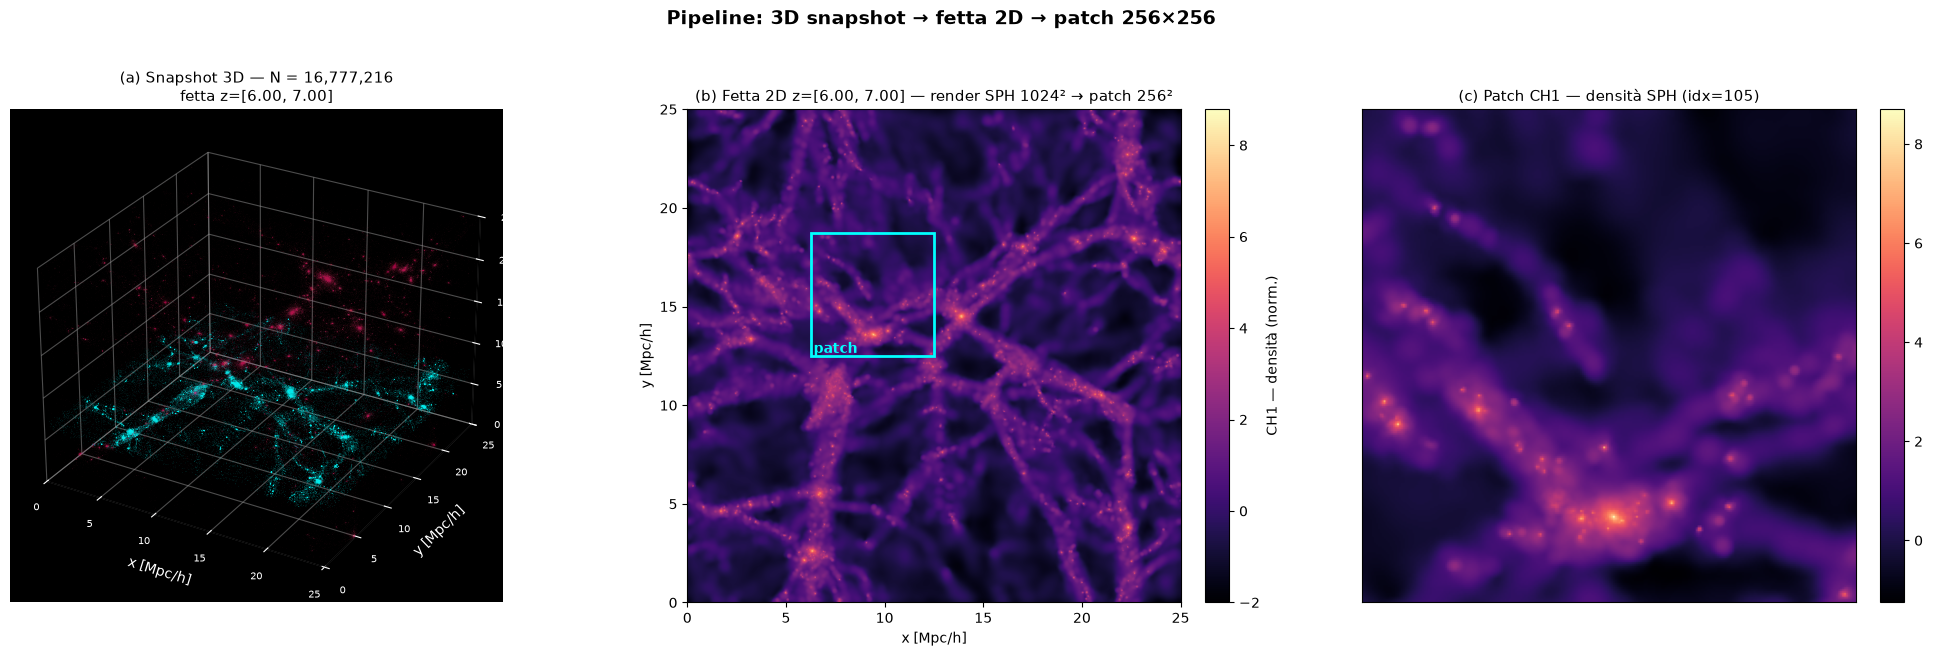

251

In [12]:
# ============================================================
# 11.1 — PIPELINE 3D → FETTA 2D → PATCH
# ============================================================
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

EX_TAG, EX_PATCH_IDX = "LH_105_090", 105     # stessa sim di nb3
N_SCATTER_OUT, N_SCATTER_IN = 200_000, 120_000

# --- coordinate della patch scelta ---
ex_dir     = os.path.join(OUT_ROOT, f"sim_{EX_TAG}")
X_ex       = np.load(os.path.join(ex_dir, "X_patches.npy"), mmap_mode="r")
n_grid     = IMG_SIZE // PATCH_SIZE
per_slice  = n_grid ** 2
slice_idx  = EX_PATCH_IDX // per_slice
grid_y, grid_x = divmod(EX_PATCH_IDX % per_slice, n_grid)

# --- coordinate 3D della fetta ---
snap_path_ex = SIMULATIONS[EX_TAG][0]
with h5py.File(snap_path_ex, "r") as f:
    pos_ex  = f["PartType1/Coordinates"][:].astype(np.float32) / 1000.0
    lbox_ex = float(np.ravel(f["Header"].attrs["BoxSize"])[0]) / 1000.0

dz_ex = lbox_ex / N_SLICES
z_lo, z_hi = slice_idx * dz_ex, (slice_idx + 1) * dz_ex
in_slice = (pos_ex[:, 2] >= z_lo) & (pos_ex[:, 2] < z_hi)

rng = np.random.default_rng(0)
idx_in  = rng.choice(np.flatnonzero( in_slice), size=min(N_SCATTER_IN,  in_slice.sum()),  replace=False)
idx_out = rng.choice(np.flatnonzero(~in_slice), size=min(N_SCATTER_OUT, (~in_slice).sum()), replace=False)

# --- ricostruisci la fetta intera da X (per il pannello b) ---
slice_img = np.zeros((IMG_SIZE, IMG_SIZE), dtype=np.float32)
for k in range(per_slice):
    gy, gx = divmod(k, n_grid)
    slice_img[gy*PATCH_SIZE:(gy+1)*PATCH_SIZE, gx*PATCH_SIZE:(gx+1)*PATCH_SIZE] = X_ex[slice_idx*per_slice + k, 0]

patch_ex = np.asarray(X_ex[EX_PATCH_IDX, 0])
px_mpc   = lbox_ex / IMG_SIZE

# --- plot ---
fig = plt.figure(figsize=(20, 6.3))
fig.suptitle("Pipeline: 3D snapshot → fetta 2D → patch 256×256", fontsize=14, fontweight="bold")

ax1 = fig.add_subplot(1, 3, 1, projection="3d"); ax1.set_facecolor("black")
for axis in (ax1.xaxis, ax1.yaxis, ax1.zaxis):
    axis.set_pane_color((0,0,0,1)); axis.label.set_color("white")
    try: axis._axinfo["grid"]["color"] = (0.6, 0.6, 0.6, 0.5)
    except Exception: pass
ax1.tick_params(colors="white", labelsize=7)
ax1.scatter(pos_ex[idx_out,0], pos_ex[idx_out,1], pos_ex[idx_out,2],
            s=0.15, c="#e0457b", alpha=0.35, linewidths=0)
ax1.scatter(pos_ex[idx_in, 0], pos_ex[idx_in, 1], pos_ex[idx_in, 2],
            s=0.15, c="cyan", alpha=0.60, linewidths=0)
ax1.set_xlim(0, lbox_ex); ax1.set_ylim(0, lbox_ex); ax1.set_zlim(0, lbox_ex)
ax1.set_xlabel("x [Mpc/h]"); ax1.set_ylabel("y [Mpc/h]"); ax1.set_zlabel("z [Mpc/h]")
ax1.view_init(elev=28, azim=-60)
ax1.set_title(f"(a) Snapshot 3D — N = {len(pos_ex):,}\nfetta z=[{z_lo:.2f}, {z_hi:.2f}]", fontsize=11)

ax2 = fig.add_subplot(1, 3, 2)
im2 = ax2.imshow(slice_img, origin="lower", extent=[0, lbox_ex, 0, lbox_ex], cmap="magma")
ax2.add_patch(Rectangle((grid_x*PATCH_SIZE*px_mpc, grid_y*PATCH_SIZE*px_mpc),
                        PATCH_SIZE*px_mpc, PATCH_SIZE*px_mpc, fill=False, edgecolor="cyan", linewidth=2))
ax2.text(grid_x*PATCH_SIZE*px_mpc + 0.15, grid_y*PATCH_SIZE*px_mpc + 0.15, "patch",
         color="cyan", fontsize=10, fontweight="bold")
ax2.set_xlabel("x [Mpc/h]"); ax2.set_ylabel("y [Mpc/h]")
ax2.set_title(f"(b) Fetta 2D z=[{z_lo:.2f}, {z_hi:.2f}] — render SPH {IMG_SIZE}² → patch {PATCH_SIZE}²", fontsize=11)
fig.colorbar(im2, ax=ax2, fraction=0.046, pad=0.04, label="CH1 — densità (norm.)")

ax3 = fig.add_subplot(1, 3, 3)
im3 = ax3.imshow(patch_ex, origin="lower", cmap="magma")
ax3.set_xticks([]); ax3.set_yticks([])
ax3.set_title(f"(c) Patch CH1 — densità SPH (idx={EX_PATCH_IDX})", fontsize=11)
fig.colorbar(im3, ax=ax3, fraction=0.046, pad=0.04)

plt.tight_layout(rect=[0, 0, 1, 0.94]); plt.show()
del pos_ex; gc.collect()

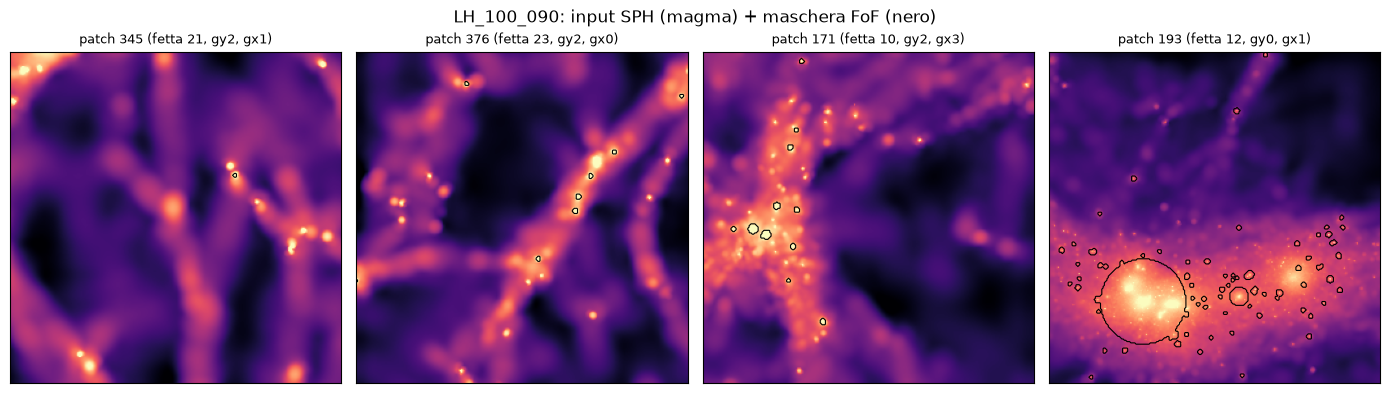

In [13]:
# ============================================================
# 11.2 — SANITY: 4 patch con contorno della maschera FoF
# ============================================================
sim_id = "LH_100_090"                             
d = os.path.join(OUT_ROOT, f"sim_{sim_id}")
X = np.load(os.path.join(d, "X_patches.npy"), mmap_mode="r")
Y = np.load(os.path.join(d, "Y_mask_patches.npy"), mmap_mode="r")

frac = Y[:, 0].sum(axis=(1, 2))
pos_idx = np.flatnonzero(frac > 0)
order = np.argsort(frac[pos_idx])
show = pos_idx[order[[0, len(order) // 3, 2 * len(order) // 3, -1]]]

fig, axes = plt.subplots(1, 4, figsize=(14, 4))
for ax, i in zip(axes, show):
    x = X[i, 0]
    ax.imshow(x, cmap="magma", vmin=np.percentile(x, 0.2), vmax=np.percentile(x, 99.8))
    ax.contour(Y[i, 0], levels=[0.5], colors="black", linewidths=0.8)
    ax.set_title(f"patch {i} (fetta {i // 16}, gy{(i % 16) // 4}, gx{i % 4})", fontsize=9)
    ax.set_xticks([]); ax.set_yticks([])
fig.suptitle(f"{sim_id}: input SPH (magma) + maschera FoF (nero)")
plt.tight_layout(); plt.show()

  catalogo: 12,846 aloni totali, 4,427 sopra il taglio (1.186e+10 Msun/h)


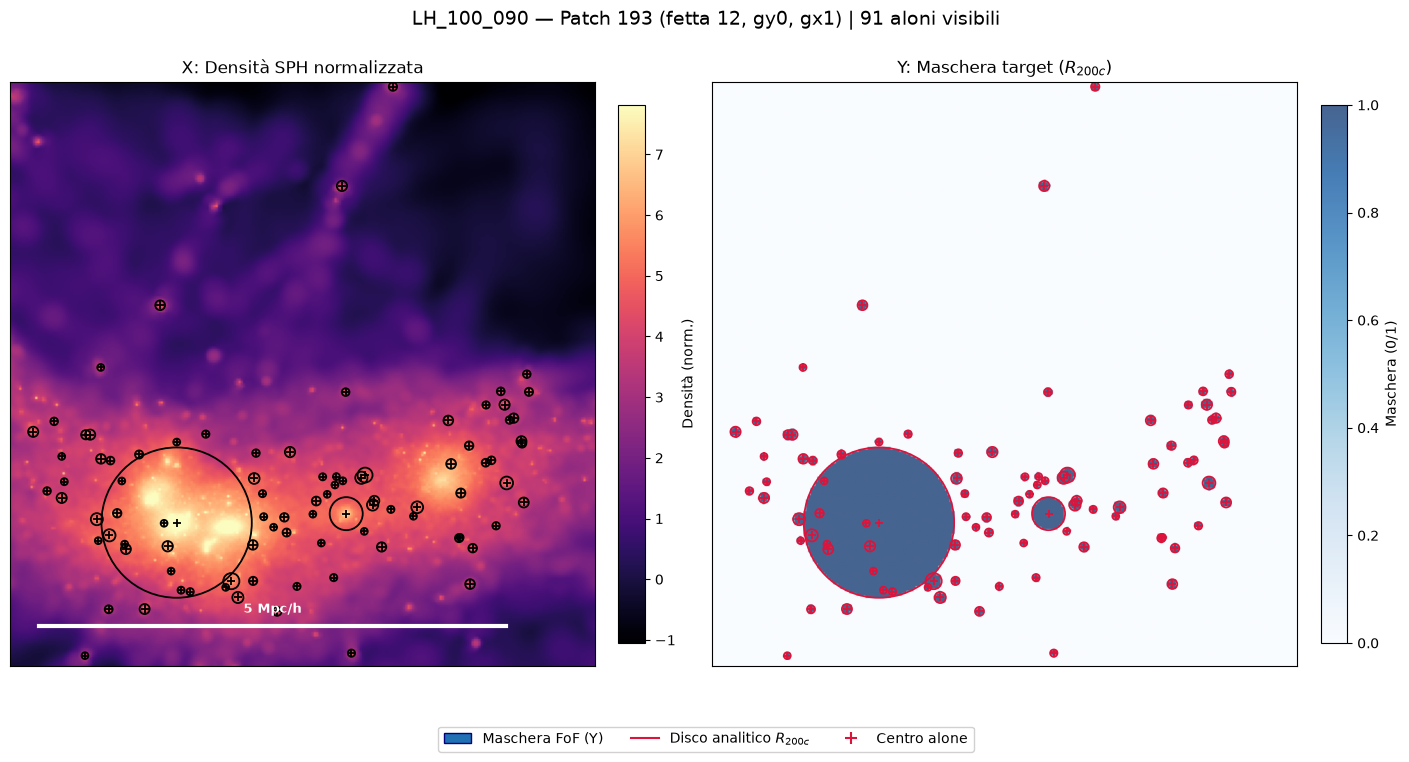

In [14]:
from matplotlib.patches import Circle, Patch
from matplotlib.lines import Line2D
from matplotlib.collections import PatchCollection

sim_id = "LH_100_090"
d = os.path.join(OUT_ROOT, f"sim_{sim_id}")

X = np.load(os.path.join(d, "X_patches.npy"), mmap_mode="r")
Y = np.load(os.path.join(d, "Y_mask_patches.npy"), mmap_mode="r")

frac = Y[:, 0].sum((1, 2))
idx = np.flatnonzero(frac > 0)[np.argmax(frac[frac > 0])]
x_patch, y_patch = X[idx, 0], Y[idx, 0]

run = sim_id.rsplit("_", 1)[0]
snap = os.path.join(
    SIM_ROOT, run, f"snapshots_{run}", f"snapshot_{SNAP_TAG}_{run}.hdf5"
)
cat = os.path.join(
    SIM_ROOT, run, f"groups_{run}", f"groups_{SNAP_TAG}_{run}.hdf5"
)

with h5py.File(snap) as f:
    lbox = np.ravel(f["Header"].attrs["BoxSize"])[0] / 1000
    m_dm = np.asarray(f["Header"].attrs["MassTable"])[1] * 1e10

xyz, r200, _, _ = load_halo_catalog(cat, N_MIN_PARTICLES * m_dm)

px, dz = IMG_SIZE / lbox, lbox / N_SLICES
ng = IMG_SIZE // PATCH_SIZE
s, g = divmod(idx, ng**2)
gy, gx = divmod(g, ng)
x0, y0 = gx * PATCH_SIZE, gy * PATCH_SIZE

keep = np.floor(xyz[:, 2] / dz).astype(int) == s
cx, cy = xyz[keep, :2].T * px
R = np.maximum(r200[keep] * px, MIN_RADIUS_PX)

vis = (
    (cx > x0 - R) & (cx < x0 + PATCH_SIZE + R) &
    (cy > y0 - R) & (cy < y0 + PATCH_SIZE + R)
)

cx, cy, R = cx[vis] - x0 - .5, cy[vis] - y0 - .5, R[vis]
circles = [Circle((x, y), r) for x, y, r in zip(cx, cy, R)]

fig, ax = plt.subplots(1, 2, figsize=(14, 7), constrained_layout=True)

vmin, vmax = np.percentile(x_patch, [.2, 99.8])
ims = [
    ax[0].imshow(x_patch, cmap="magma", vmin=vmin, vmax=vmax),
    ax[1].imshow(y_patch, cmap="Blues", vmin=0, vmax=1, alpha=.75)
]

for a, color in zip(ax, ("black", "crimson")):
    a.add_collection(PatchCollection(
        circles, facecolor="none", edgecolor=color, linewidth=1.3
    ))
    a.plot(cx, cy, "+", color=color, ms=6, mew=1.3)
    a.set(xlim=(-.5, PATCH_SIZE-.5), ylim=(PATCH_SIZE-.5, -.5),
          xticks=[], yticks=[])
    a.grid(True, color="gray", alpha=.25, linestyle=":", linewidth=.5)

ax[0].set_title("X: Densità SPH normalizzata")
ax[1].set_title(r"Y: Maschera target ($R_{200c}$)")

for a, im, label in zip(
    ax, ims, ("Densità (norm.)", "Maschera (0/1)")
):
    fig.colorbar(im, ax=a, fraction=.046, pad=.04, label=label)

xb, yb = 12, PATCH_SIZE - 18
ax[0].plot([xb, xb + 5 * px], [yb, yb], color="white", lw=3)
ax[0].text(xb + 2.5 * px, yb - 6, "5 Mpc/h",
           ha="center", color="white", fontsize=9, weight="bold")

fig.legend(
    [Patch(facecolor=plt.colormaps["Blues"](.75), edgecolor="navy"),
     Line2D([], [], color="crimson", lw=1.5),
     Line2D([], [], marker="+", color="crimson", lw=0, ms=8, mew=1.5)],
    ["Maschera FoF (Y)", r"Disco analitico $R_{200c}$", "Centro alone"],
    loc="lower center", ncol=3, bbox_to_anchor=(.5, -.05), framealpha=.9
)

fig.suptitle(
    f"{sim_id} — Patch {idx} (fetta {s}, gy{gy}, gx{gx}) | "
    f"{len(cx)} aloni visibili",
    fontsize=14, y=1.02
)

plt.show()